# Retail Sales Forecasting & Operational Planning

Locally executed companion evidence notebook. It reads measured outputs; it does not rerun training or claim execution on Kaggle.

UCI Online Retail II; Chen; DOI 10.24432/C5CG6D; CC BY 4.0. AI-assisted portfolio study; no independently verified personal-skill claim.

Planning analyst reviews next week’s positive observed sales and uncertainty. No inventory, margin or latent-demand inference.

In [1]:
from pathlib import Path
import json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/common.py').exists())
CASE = ROOT / 'projects/PRJ2_retail'
metrics = json.loads((CASE / 'results/metrics.json').read_text(encoding='utf-8'))
print(json.dumps(metrics, indent=2))

{
  "diagnostics": {
    "cancelled_lines": 19494,
    "negative_quantity_lines": 22950,
    "negative_quantity_signed_value_GBP": -1527041.43,
    "positive_before_dedup_rows": 1041670,
    "positive_duplicate_rows": 33757,
    "target": "positive recorded sales value, GBP; not net revenue or latent demand"
  },
  "primary": "retain_ambiguous_duplicates",
  "variants": {
    "retain_ambiguous_duplicates": {
      "last_week": {
        "n": 26,
        "MAE": 46271.53576923077,
        "WAPE": 0.20045408158975095,
        "bias_actual_minus_forecast": 7910.851923076924
      },
      "mean_4": {
        "n": 26,
        "MAE": 35291.92109615384,
        "WAPE": 0.152889017259975,
        "bias_actual_minus_forecast": 17089.794903846156
      },
      "ridge_log_lags": {
        "n": 26,
        "MAE": 38638.14422680151,
        "WAPE": 0.16738527447939494,
        "bias_actual_minus_forecast": 7914.996465437765
      },
      "seasonal_52": {
        "n": 26,
        "MAE": 40170.6603

In [2]:
for name in ['sql_check.json']:
    print(name)
    print(json.dumps(json.loads((CASE / 'results' / name).read_text(encoding='utf-8')), indent=2))

sql_check.json
{
  "sql_total_GBP": 20972594.568,
  "pandas_total_GBP": 20972594.567999996,
  "weekly_labels_and_values_match": true,
  "weeks_reconciled": 106,
  "passed": true
}


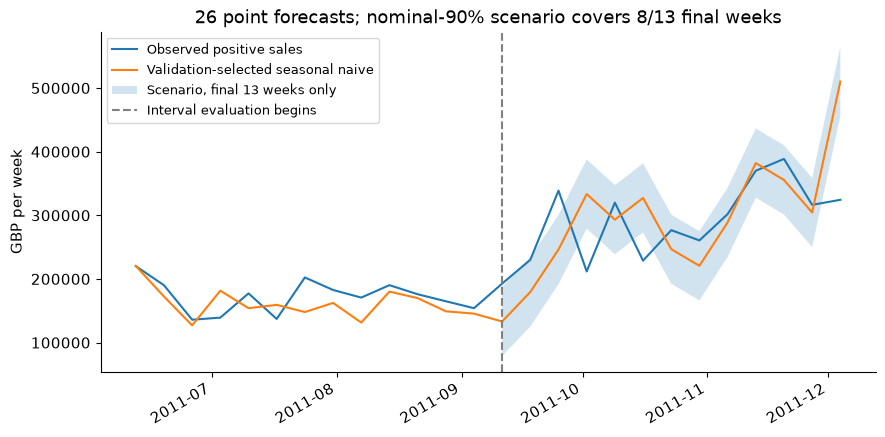

In [3]:
from IPython.display import Image, display
display(Image(filename=str(CASE / 'figures/backtest.png')))

## Interpretation and full recomputation

Validation selected seasonal_52. On 26 held-out one-week origins: MAE £40,170.66, WAPE 17.40%, signed bias £3,040.39. Separate interval evaluation: 61.54% coverage on 13 weeks. Exact-dedup seasonal WAPE 14.34% is a sensitivity, not a reason to alter the target.

Thirteen selection weeks; 26 point-forecast test weeks split into 13 calibration and 13 interval-evaluation weeks. The nominal 90% scenario fails to achieve that coverage; no 90% reliability guarantee. Annual history is short and duplicates ambiguous. Mean-4 is better on this test, but no test-driven model switch is made. Costs are hypothetical.

From the portfolio root, use the environment and authorised inputs in `docs/REPRODUCIBILITY.md`, then execute `python src/retail_production.py`. Do not rerun the data audits merely to read these results. A standalone Kaggle environment requires adapting input mounting and installing the documented dependencies; no hosted execution is claimed.